<a href="https://colab.research.google.com/github/spolishchuk8-stack/goit-rdb-hw-05/blob/main/%D0%A2%D0%B5%D0%BC%D0%B0_1_2_%D0%9B%D0%BE%D0%B3%D1%96%D1%81%D1%82%D0%B8%D1%87%D0%BD%D0%B0_%D1%80%D0%B5%D0%B3%D1%80(v1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

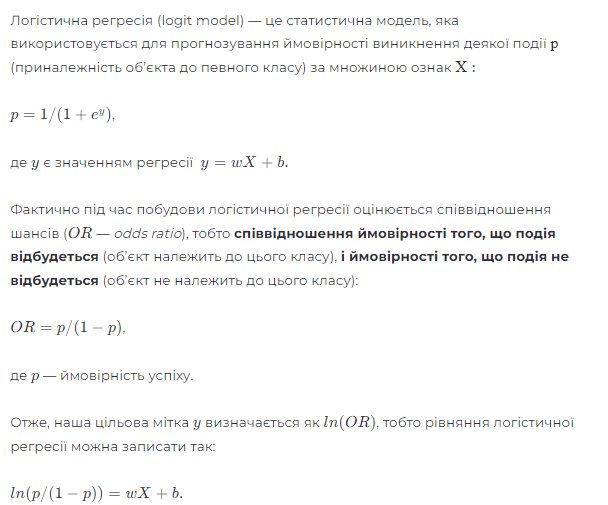

Задача 1.
Провести попередній аналіз даних. Побудувати логістичну регресію для датасета гриби

https://drive.google.com/file/d/1EM37ZlZNmTS7BpAOEoKyn65jfv1bxaOR/view?usp=drive_link

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [ ]:
from google.colab import files

# Завантаження файлу
uploaded = files.upload()

Saving mushroom.csv to mushroom.csv


In [ ]:
df = pd.read_csv('mushroom.csv')
df

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season,class
0,1372,2,2,10,3.807467,1545,11,1.804273,1
1,1461,2,2,10,3.807467,1557,11,1.804273,1
2,1371,2,2,10,3.612496,1566,11,1.804273,1
3,1261,6,2,10,3.787572,1566,11,1.804273,1
4,1305,6,2,10,3.711971,1464,11,0.943195,1
...,...,...,...,...,...,...,...,...,...
54030,73,5,3,2,0.887740,569,12,0.943195,1
54031,82,2,3,2,1.186164,490,12,0.943195,1
54032,82,5,3,2,0.915593,584,12,0.888450,1
54033,79,2,3,2,1.034963,491,12,0.888450,1


Цей набір даних є очищеною версією оригінального набору даних Mushroom для бінарної класифікації. Він містить 9 колонок:

**cap-diameter**	-	діаметр шапки гриба в сантиметрах або міліметрах.

**cap-shape**	-	форма шапки гриба.

**gill-attachment**	- спосіб прикріплення пластинок до ніжки.

**gill-color**	- колір пластинок під шапкою гриба.

**stem-height**	- висота ніжки гриба.

**stem-width**	- ширина ніжки гриба.

**stem-color**	- колір ніжки гриба.

**season**	- сезон, коли гриб зазвичай з’являється.

**class** -  цільова функція, містить два значення – 0 або 1, де 0 означає їстівне, а 1 – отруйне.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54035 entries, 0 to 54034
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   cap-diameter     54035 non-null  int64  
 1   cap-shape        54035 non-null  int64  
 2   gill-attachment  54035 non-null  int64  
 3   gill-color       54035 non-null  int64  
 4   stem-height      54035 non-null  float64
 5   stem-width       54035 non-null  int64  
 6   stem-color       54035 non-null  int64  
 7   season           54035 non-null  float64
 8   class            54035 non-null  int64  
dtypes: float64(2), int64(7)
memory usage: 3.7 MB


In [ ]:
df.duplicated().sum()

np.int64(303)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season,class
0,1372,2,2,10,3.807467,1545,11,1.804273,1
1,1461,2,2,10,3.807467,1557,11,1.804273,1
2,1371,2,2,10,3.612496,1566,11,1.804273,1
3,1261,6,2,10,3.787572,1566,11,1.804273,1
4,1305,6,2,10,3.711971,1464,11,0.943195,1
...,...,...,...,...,...,...,...,...,...
54030,73,5,3,2,0.887740,569,12,0.943195,1
54031,82,2,3,2,1.186164,490,12,0.943195,1
54032,82,5,3,2,0.915593,584,12,0.888450,1
54033,79,2,3,2,1.034963,491,12,0.888450,1


In [ ]:
# Визначення цільової змінної та ознак
TARGET = 'class'
FEATURES = [col for col in df.columns if col != TARGET]

# Визначення категоріальних та числових ознак
cat_features = [col for col in FEATURES if df[col].nunique() < 25]
cont_features = [col for col in FEATURES if df[col].nunique() >= 25]

# Виведення результатів
print(f'Number of categorical features: {len(cat_features)}')
print('Categorical features:', cat_features, '\n')

print(f'Number of continuous features: {len(cont_features)}')
print('Continuous features:', cont_features, '\n')

Number of categorical features: 5
Categorical features: ['cap-shape', 'gill-attachment', 'gill-color', 'stem-color', 'season'] 

Number of continuous features: 3
Continuous features: ['cap-diameter', 'stem-height', 'stem-width'] 



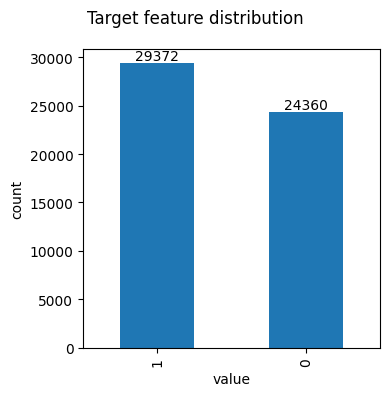

In [ ]:
ax = df[TARGET].value_counts().plot(kind='bar', figsize=(4, 4))
for i in ax.containers:
  ax.bar_label(i)
  ax.set_xlabel("value")
  ax.set_ylabel("count")

plt.suptitle("Target feature distribution")

plt.tight_layout()
plt.show()

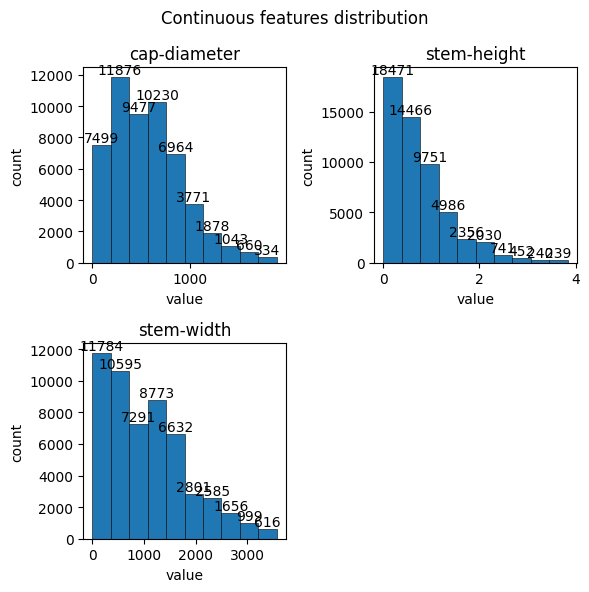

In [ ]:
#розподіл числових змінних
ax = df.loc[:, cont_features].hist(figsize=(6, 6), grid=False, edgecolor='black', linewidth=.4)
for row in ax:
  for col in row:
    for i in col.containers:
      col.bar_label(i)
      col.set_xlabel("value")
      col.set_ylabel("count")

plt.suptitle("Continuous features distribution")

plt.tight_layout()
plt.show()

In [ ]:
df.describe()

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season,class
count,53732.000000,53732.000000,53732.000000,53732.000000,53732.000000,53732.000000,53732.000000,53732.000000,53732.000000
mean,568.629178,4.005900,2.142857,7.344599,0.752102,1057.000633,8.454013,0.952322,0.546639
std,360.384461,2.165188,2.232546,3.190447,0.645987,780.263033,3.235507,0.303795,0.497825
min,0.000000,0.000000,0.000000,0.000000,0.000426,0.000000,0.000000,0.027372,0.000000
25%,290.000000,2.000000,0.000000,5.000000,0.270146,430.000000,6.000000,0.888450,0.000000
50%,528.000000,5.000000,1.000000,8.000000,0.589316,929.000000,11.000000,0.943195,1.000000
75%,782.000000,6.000000,4.000000,10.000000,1.046900,1527.000000,11.000000,0.943195,1.000000
max,1891.000000,6.000000,6.000000,11.000000,3.835320,3569.000000,12.000000,1.804273,1.000000


In [ ]:
df.isnull().sum()

,0
cap-diameter,0
cap-shape,0
gill-attachment,0
gill-color,0
stem-height,0
stem-width,0
stem-color,0
season,0
class,0


In [ ]:
df.dtypes

,0
cap-diameter,int64
cap-shape,int64
gill-attachment,int64
gill-color,int64
stem-height,float64
stem-width,int64
stem-color,int64
season,float64
class,int64


Розрахунок кореляції
Обчислення кореляції між ознаками допомагає відібрати найбільш інформативні ознаки для побудови ефективної моделі.

Ознаки, які мають високу кореляцію з цільовою змінною, можуть бути корисними для моделі.

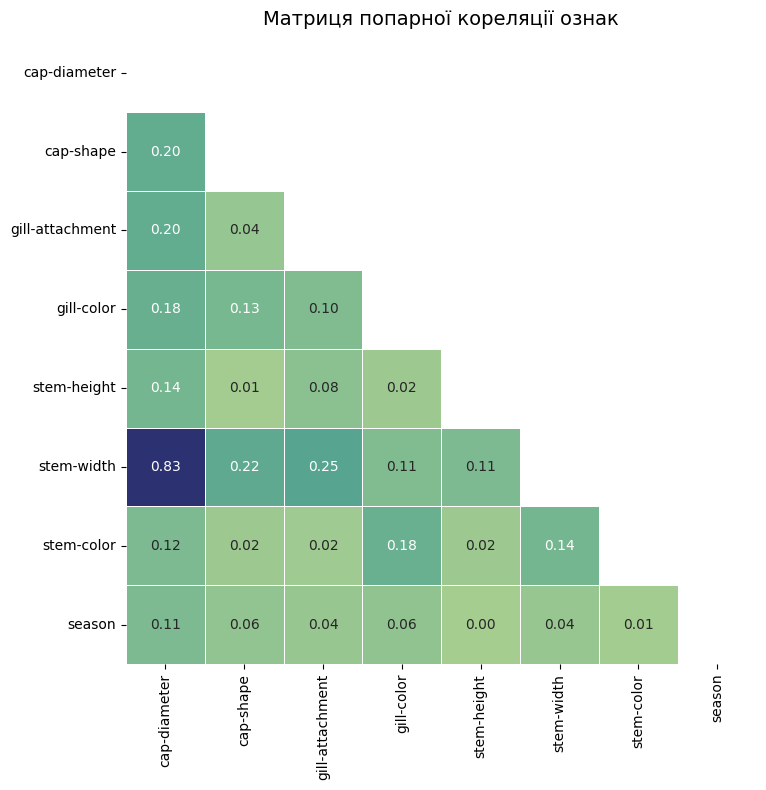

In [ ]:
mtx = df.drop('class', axis=1).corr(numeric_only=True).abs()

# Побудова теплової карти кореляції
fig, ax = plt.subplots(figsize=(8, 8))

sns.heatmap(
    mtx,
    cmap='crest',
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    mask=np.triu(np.ones_like(mtx, dtype=bool)),  # маскуємо верхній трикутник
    square=True,
    cbar=False,
    ax=ax
)

plt.title("Матриця попарної кореляції ознак", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
cor_with_class = df.corr()['class'].sort_values(ascending=False)
print("Корреляція з 'class':")
cor_with_class

Корреляція з 'class':


,class
class,1.000000
stem-height,0.175839
gill-attachment,-0.052397
gill-color,-0.060166
season,-0.083363
stem-color,-0.119940
cap-shape,-0.131385
cap-diameter,-0.162830
stem-width,-0.177310


**Логістична регресія**

In [ ]:
df.head()


,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season,class
0,1372,2,2,10,3.807467,1545,11,1.804273,1
1,1461,2,2,10,3.807467,1557,11,1.804273,1
2,1371,2,2,10,3.612496,1566,11,1.804273,1
3,1261,6,2,10,3.787572,1566,11,1.804273,1
4,1305,6,2,10,3.711971,1464,11,0.943195,1


У функції train_test_split встановимо значення аргументу stratify = y. Цей аргумент забезпечує збереження розподілу цільової змінної в наборах даних train/tets.

In [ ]:
# Поділимо дані на тренувальну і тестову вибірки
TARGET = 'class'
X = df.drop(TARGET , axis =1 )
y = df[TARGET]

X_train , X_test , y_train , y_test = train_test_split(X, y, random_state = 42, test_size =0.2, stratify=y)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Дані перетворення потрібні для правильного формату вхідних даних у нейронних мережах та інших алгоритмах машинного навчання.

 Транспонування (.T) змінює розташування даних, а np.expand_dims додає додатковий вимір, що може бути необхідним для сумісності з певними бібліотеками (наприклад, TensorFlow або PyTorch).

Навіщо потрібне транспонування? Деякі алгоритми глибокого навчання, зокрема нейромережі, працюють ефективніше, коли кожна ознака є окремим рядком, а зразки розташовані у стовпцях.

In [ ]:
#Для подальших коректних обрахунків транспонуємо матрицю вхідних ознак і вектор цільової змінної.
x_train = X_train.T
x_test = X_test.T
y_train = np.expand_dims(y_train.T, 0)
y_test = np.expand_dims(y_test.T, 0)

print('X train size', x_train.shape)
print('X test size', x_test.shape)
print('y train size', y_train.shape)
print('y test size', y_test.shape)

X train size (8, 42985)
X test size (8, 10747)
y train size (1, 42985)
y test size (1, 10747)


Нам потрібно задати початкові параметри ваг w, які будуть змінюватись під час навчання. Нехай усі значення ваг w будуть дорівнювати 0.01, а значення зміщення
b буде дорівнювати нулю.

In [ ]:
#Ініціалізація параметрів моделі
def initialize_weights_and_bias(dimension):
    # dimension - number of input features
    w = np.full((dimension,1),0.01)
    b = 0.0
    return w, b

In [ ]:
#Сигмоїда повертає значення ймовірностей
def sigmoid(z):
    y_head = 1/(1+np.exp(-z))
    return y_head

In [ ]:
#Всі кроки від передачі матриці ознак у мережу до розрахунку функції втрат називаються прямим розповсюдженням.

def forward_backward_propagation(w,b,x_train,y_train, eps=1e-5):

    # forward propagation
    z = np.dot(w.T,x_train) + b
    y_head = sigmoid(z)

    # Функція втрат для задачі бінарної класифікації -  бінарна крос-ентропія
    #Імовірнісна інтерпретація: втрата binary cross-entropy loss виводиться з розподілу ймовірностей Бернуллі,
    #який моделює ймовірність бінарного результату. Це дозволяє моделі виводити оцінки ймовірності для кожного класу.
    #Бінарна крос-ентропія є обчислювально простішою та ефективнішою, оскільки для неї потрібен лише один вихідний нейрон у нейронній мережі.

    loss = -1*y_train*np.log(y_head+eps)-(1-y_train)*np.log(1-y_head+eps)
    cost = (np.sum(loss))/x_train.shape[1]      # x_train.shape[1]  is for scaling

    # backward propagation
    #Оновлення ваг моделі шляхом розрахунку градієнта є кроком зворотного розповсюдження помилки.

    derivative_weight = (np.dot(x_train,((y_head-y_train).T)))/x_train.shape[1] # x_train.shape[1]  is for scaling
    derivative_bias = np.sum(y_head-y_train)/x_train.shape[1]                 # x_train.shape[1]  is for scaling
    gradients = {"derivative_weight": derivative_weight,"derivative_bias": derivative_bias}
    return cost, gradients

    #Функція буде повертати значення функції витрат cost і змінну gradients, що буде містити значення похідних

In [ ]:
def compute_accuracy(y_head, y_train):
    predictions = (y_head > 0.5).astype(int)  # Бінарне перетворення ймовірностей у класи
    accuracy = np.mean(predictions == y_train)  # Середня точність
    return accuracy

In [ ]:
#Кожної епохи модель буде обробляти тільки один батч розмірністю [кількість вхідних ознак, кількість прикладів
def update(w, b, x_train, y_train, learning_rate, number_of_iterations):
    cost_list = []
    accuracy_list = []
    index = []

    for i in range(number_of_iterations):
        cost, gradients = forward_backward_propagation(w, b, x_train, y_train)
        y_head = sigmoid(np.dot(w.T, x_train) + b)
        accuracy = compute_accuracy(y_head, y_train)

        cost_list.append(cost)
        accuracy_list.append(accuracy)
        index.append(i)

        w = w - learning_rate * gradients["derivative_weight"]
        b = b - learning_rate * gradients["derivative_bias"]

    parameters = {"weight": w, "bias": b}

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(index, cost_list, label='Cost')
    plt.xticks(index, rotation='vertical')
    plt.xlabel("Number of Iterations")
    plt.ylabel("Cost")
    plt.title('Графік функції втрат')
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(index, accuracy_list, label='Accuracy', color='orange')
    plt.xticks(index, rotation='vertical')
    plt.xlabel("Number of Iterations")
    plt.ylabel("Accuracy")
    plt.title('Графік точності')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    return parameters, gradients, cost_list, accuracy_list

In [ ]:
def predict(w,b,x_test):
    # x_test is a input for forward propagation

    z = sigmoid(np.dot(w.T,x_test)+b)
    Y_prediction = np.zeros((1,x_test.shape[1]))

    # if z is bigger than 0.5, our prediction is sign one (y_head=1),
    # if z is smaller than 0.5, our prediction is sign zero (y_head=0),
    for i in range(z.shape[1]):
        if z[0,i]<= 0.5:
            Y_prediction[0,i] = 0
        else:
            Y_prediction[0,i] = 1

    return Y_prediction

In [ ]:
def logistic_regression(x_train, y_train, x_test, y_test, learning_rate, num_iterations):
    # Ініціалізація
    dimension = x_train.shape[0]
    w, b = initialize_weights_and_bias(dimension)

    # Оновлення параметрів і отримання всіх значень
    parameters, gradients, cost_list, accuracy_list = update(w, b, x_train, y_train, learning_rate, num_iterations)

    # Прогнозування
    y_prediction_test = predict(parameters["weight"], parameters["bias"], x_test)
    y_prediction_train = predict(parameters["weight"], parameters["bias"], x_train)

    # Розрахунок точності
    train_accuracy = np.mean(y_prediction_train == y_train) * 100
    test_accuracy = np.mean(y_prediction_test == y_test) * 100

    # Виведення точності
    print("Train accuracy: {:.2f} %".format(train_accuracy))
    print("Test accuracy: {:.2f} %".format(test_accuracy))

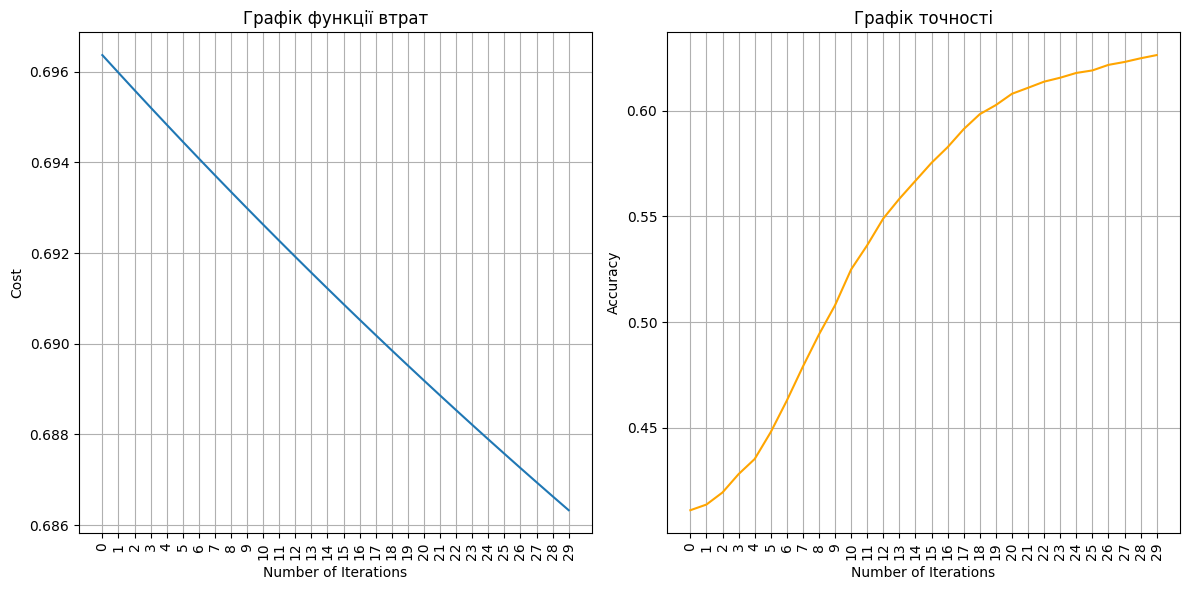

Train accuracy: 62.74 %
Test accuracy: 63.17 %


In [ ]:
logistic_regression(x_train, y_train, x_test, y_test,learning_rate = 0.01, num_iterations = 30)

Реалізація логістичної регресії sk learn

In [ ]:
df.head()

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season,class
0,1372,2,2,10,3.807467,1545,11,1.804273,1
1,1461,2,2,10,3.807467,1557,11,1.804273,1
2,1371,2,2,10,3.612496,1566,11,1.804273,1
3,1261,6,2,10,3.787572,1566,11,1.804273,1
4,1305,6,2,10,3.711971,1464,11,0.943195,1


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
X = df.drop('class', axis=1)
y = df['class']

# Розділяємо на навчальні та тестові дані
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
log_reg = LogisticRegression()

# Визначаємо сітку параметрів для пошуку
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],  # параметр регуляризації
    'solver': ['lbfgs', 'liblinear'],  # алгоритми оптимізації
    'max_iter': [100, 200, 300]  # кількість ітерацій
}

# Використовуємо GridSearchCV для пошуку найкращих параметрів
grid_search = GridSearchCV(log_reg, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

# Отримуємо найкращі параметри
best_params = grid_search.best_params_
print("Найкращі параметри: ", best_params)

Найкращі параметри:  {'C': 0.01, 'max_iter': 100, 'solver': 'liblinear'}


In [ ]:
# Прогнозуємо, використовуючи найкращу модель
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

In [ ]:
print (classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.59      0.53      0.56      4783
           1       0.65      0.70      0.67      5964

    accuracy                           0.62     10747
   macro avg       0.62      0.62      0.62     10747
weighted avg       0.62      0.62      0.62     10747



In [ ]:
# Отримуємо DataFrame з тестовими даними, справжніми та прогнозованими результатами
results = pd.DataFrame({
    'True Label': y_test,
    'Predicted Label': y_pred
})

# Вибираємо 10 випадкових прикладів
random_indices = np.random.choice(results.index, 10, replace=False)
random_results = results.loc[random_indices]
random_results

,True Label,Predicted Label
9061,1,1
18388,1,1
578,1,1
24562,1,0
24726,1,0
15523,0,1
37938,1,1
36107,1,1
33009,1,1
48765,0,0


In [ ]:
model = LogisticRegression(class_weight='balanced')
model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced')

In [ ]:
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.57      0.65      0.61      4783
           1       0.69      0.61      0.65      5964

    accuracy                           0.63     10747
   macro avg       0.63      0.63      0.63     10747
weighted avg       0.64      0.63      0.63     10747



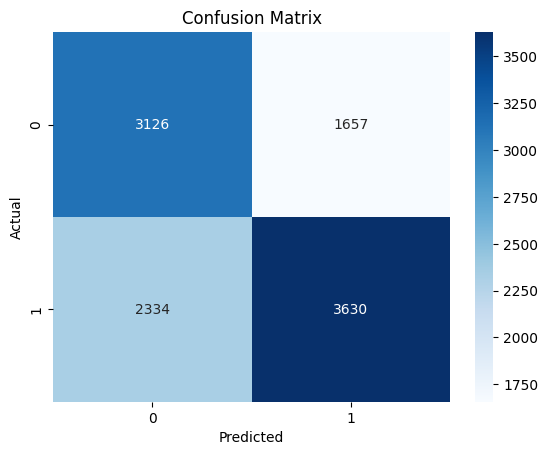

In [ ]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()